In [1]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, boxcox

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for univariate and multivariate audits loaded successfully.")

Global libraries for univariate and multivariate audits loaded successfully.


### 1. Deep-Dive Distribution Visualization (KDE, Boxen, Violin)


                mean           min            max
salary  69569.985761  39649.830278  103522.781845
____________________________________________________________
                    mean           min            max
department                                           
HR          55178.436696  39649.830278   76761.353333
IT          83961.534826  58802.548959  103522.781845


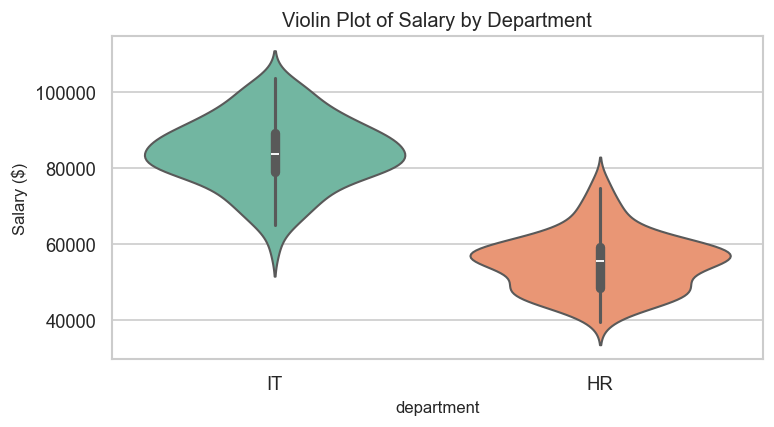

In [5]:
np.random.seed(42)
df_dist = pd.DataFrame({
    'department': ['IT'] * 100 + ['HR'] * 100,
    'salary': np.concatenate([np.random.normal(85000, 10000, 100), np.random.normal(55000, 8000, 100)])
})
# print(df_dist.head())
print(df_dist.describe().T[['mean','min','max']])
print("_" * 60)
print(df_dist.groupby('department')['salary'].describe()[['mean', 'min', 'max']])
plt.figure(figsize=(7, 3.5))
sns.violinplot(x = 'department', y='salary', data=df_dist, hue='department', palette='Set2',legend=False)
plt.title("Violin Plot of Salary by Department")
plt.ylabel("Salary ($)")
plt.show()

### 2. Joint Distributions and Pairplots

   feature_a  feature_b category
0  10.993428  12.923146  Group 2
1   9.723471  17.896773  Group 2
2  11.295377  18.286427  Group 1
3  13.046060  15.988614  Group 2
4   9.531693  19.193571  Group 1
Correlation matrix:
            feature_a  feature_b
feature_a   1.000000  -0.136422
feature_b  -0.136422   1.000000


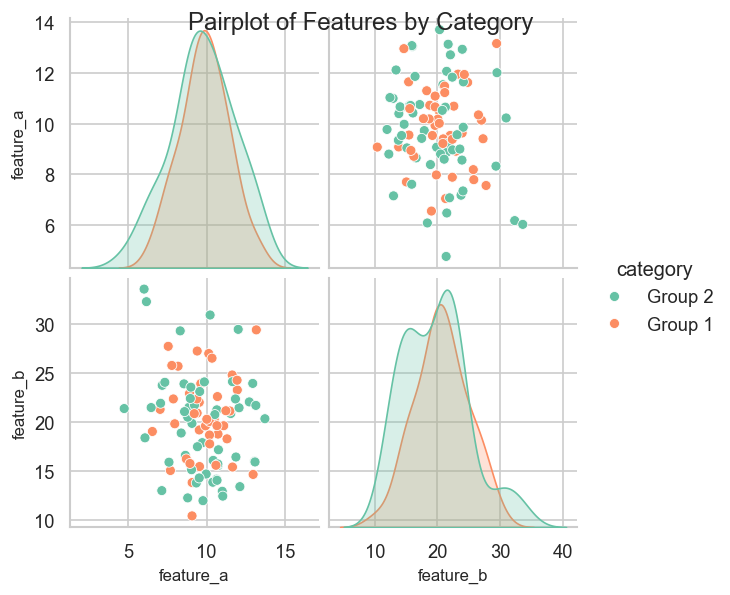

In [8]:
np.random.seed(42)

df_joint = pd.DataFrame({
    'feature_a': np.random.normal(10, 2, 100),
    'feature_b': np.random.normal(20, 5, 100),
    'category': np.random.choice(['Group 1', 'Group 2'], 100)
})
print(df_joint.head())
print("Correlation matrix:\n", df_joint[['feature_a', 'feature_b']].corr())

# visualization
sns.pairplot(df_joint, hue='category', palette='Set2')
plt.suptitle("Pairplot of Features by Category")
plt.show()

Correlation Matrix:
             income  expenses
income    1.000000 -0.136422
expenses -0.136422  1.000000


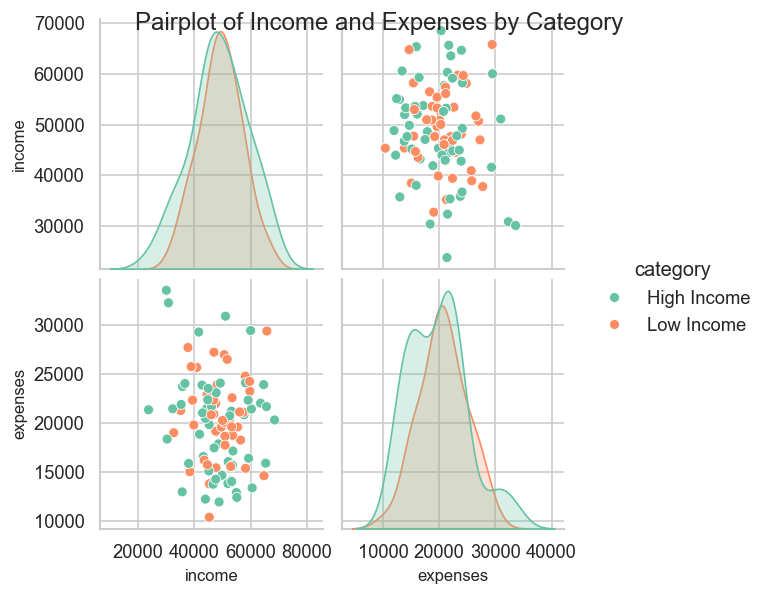

In [9]:
np.random.seed(42)
# let us change feature_a and feature_b to income and expenses and change distribution parameters accordingly
# let us change the category also
# we will use 'Low Income' and 'High Income' as the new categories
# change the column names and the correlation matrix accordingly
df_joint = pd.DataFrame({
    'income': np.random.normal(50000, 10000, 100),
    'expenses': np.random.normal(20000, 5000, 100),
    'category': np.random.choice(['Low Income', 'High Income'], 100)
})
# print(df_joint.head())
print("Correlation Matrix:\n", df_joint[['income', 'expenses']].corr())

# visualization
sns.pairplot(df_joint, hue='category', palette='Set2')
plt.suptitle("Pairplot of Income and Expenses by Category")
plt.show()

### 3. Categorical vs Continuous Breakdown Analysis

  region  sales
0  North    250
1  North    300
2  South    450
3  South    400
4   East    150
5   East    180
Segment Summary:
 region  mean  median       std
  East 165.0   165.0 21.213203
 North 275.0   275.0 35.355339
 South 425.0   425.0 35.355339


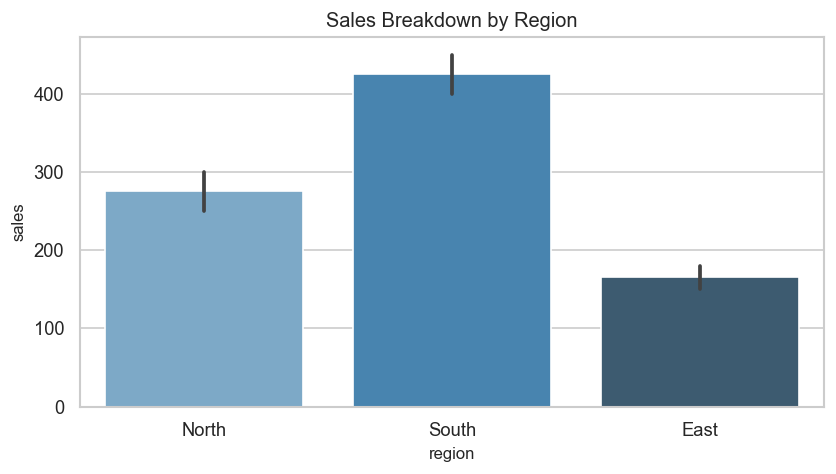

In [ ]:
df_breakdown = pd.DataFrame({
    'region': ['North', 'North', 'South', 'South', 'East', 'East'],
    'sales': [250,300, 450, 400, 150, 180]
})
print(df_breakdown)
segment_summary = df_breakdown.groupby('region')['sales'].agg(['mean', 'median', 'std']).reset_index()
print("Segment Summary:\n", segment_summary.to_string(index=False))

# visualization
# palette for the bar plot : muted , deep, pastel, bright, dark, colorblind, Blues_d,
sns.barplot(x='region', y='sales', data=df_breakdown,  palette='Blues_d', hue='region',legend=False)
plt.title("Sales Breakdown by Region")
plt.show()

### 4. Skewness and Transformation Checks

Original Skewness: 1.4409012249947706
Log-Transformed Skewness: 0.33730012283200667


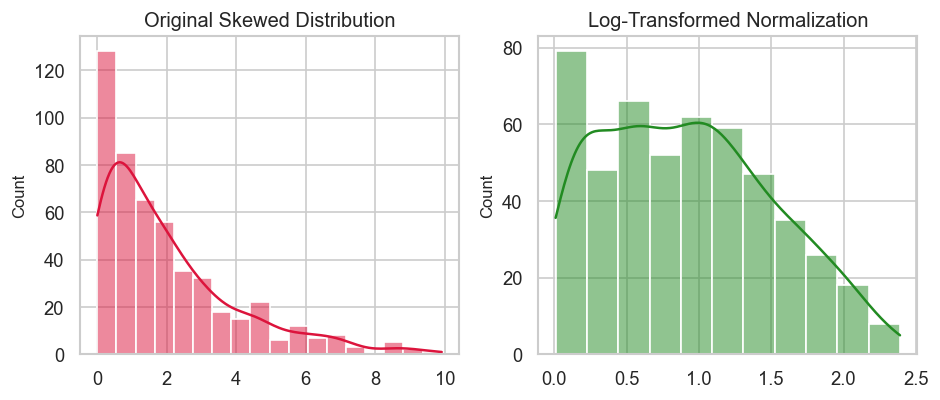

In [21]:
np.random.seed(42)
skewed_data = np.random.exponential(scale=2.0, size=500)
log_transformed = np.log1p(skewed_data)

print("Original Skewness:", skew(skewed_data))
print("Log-Transformed Skewness:", skew(log_transformed))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
sns.histplot(skewed_data, kde=True, ax=axes[0], color='crimson')
axes[0].set_title('Original Skewed Distribution')
sns.histplot(log_transformed, kde=True, ax=axes[1], color='forestgreen')
axes[1].set_title('Log-Transformed Normalization')
plt.tight_layout()
plt.show()